<table>
  <tr>
    <td><div align="left"><font size="30">Chapter 6:<br>Localization and Mapping</font></div></td>
    <td><img src="https://github.com/petercorke/RVC3-python/raw/main/figures/RVC3P-cover.png?raw=1" width="200"></td>
  </tr>
</table>

<span style="font-size:150%">Robotics, Vision & Control 3e: for Python</span>

Copyright © 2021- Peter Corke

In [1]:
try:
    import google.colab
    print('Running on CoLab')
    COLAB = True
    #!pip install roboticstoolbox-python>=1.0.2
    !pip install git+https://github.com/petercorke/robotics-toolbox-python@future
    !pip install spatialmath-python>=1.1.5
    !pip install --no-deps rvc3python
except ModuleNotFoundError:
    COLAB = False

from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "last_expr_or_assign"

In [2]:
from IPython.display import HTML

import matplotlib.pyplot as plt

# add RTB examples folder to the path
import sys, os.path
import RVC3 as rvc
sys.path.append(os.path.join(rvc.__path__[0], 'models'))

# ------ standard imports ------ #
import numpy as np
import math
from math import pi
np.set_printoptions(
    linewidth=120, formatter={
        'float': lambda x: f"{0:8.4g}" if abs(x) < 1e-10 else f"{x:8.4g}"})
np.random.seed(0)
from spatialmath import *
from spatialmath.base import *
from roboticstoolbox import *

There are some minor code changes compared to the book. These are to support 
animations in the Jupyter environment. Animations can be made using `FuncAnimation` and
the `widget` backend, but with Colab these can be very unsmooth.  Instead we render the 
animations to HTML5 and render them locally in the browser.

# 6.1 Dead Reckoning using Odometry


## 6.1.1 Modeling the Robot


In [3]:
V = np.diag([0.02, np.deg2rad(0.5)]) ** 2;

In [4]:
robot = Bicycle(covar=V, animation="car")

Bicycle: x = [ 0, 0, 0 ]
  L=1, steer_max=1.41372, speed_max=inf, accel_max=inf

In [5]:
odo = robot.step((1, 0.3))

array([  0.1025,  0.02978])

In [6]:
robot.q

array([     0.1,        0,  0.03093])

In [7]:
robot.f([0, 0, 0], odo)

array([  0.1025,        0,  0.02978])

In [8]:
robot.control = RandomPath(workspace=10)

In [9]:
# robot.run(T=10);

html = robot.run_animation(T=20, format="html");
HTML(html)

## 6.1.2 Estimating Pose


In [10]:
robot.Fx([0, 0, 0], [0.5, 0.1])

array([[       1,        0,        0],
       [       0,        1,      0.5],
       [       0,        0,        1]])

In [11]:
x_sdev = [0.05, 0.05, np.deg2rad(0.5)];
P0 = np.diag(x_sdev) ** 2;

EKF object: 3 states, estimating: vehicle pose, map
  robot: Bicycle: x = [ 0, 0, 0 ]
    L=1, steer_max=1.41372, speed_max=inf, accel_max=inf
  V_est:  [ 0.0004, 0 | 0, 7.62e-05 ]

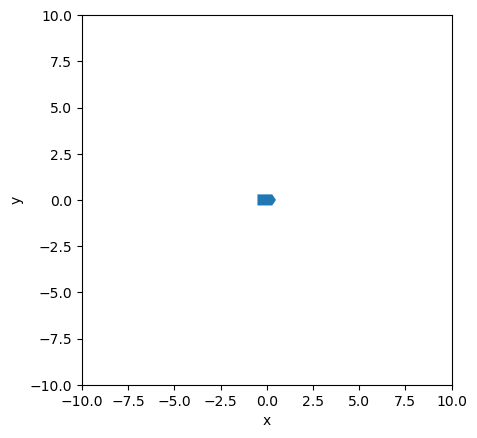

In [12]:
ekf = EKF(robot=(robot, V), P0=P0)

In [66]:
ekf.run?

Signature: ekf.run(T, animate=False)
Docstring:
Run the EKF simulation

:param T: maximum simulation time in seconds
:type T: float
:param animate: animate motion of vehicle, defaults to False
:type animate: bool, optional

Simulates the motion of a vehicle (under the control of a driving agent)
and the EKF estimator.  The steps are:

- initialize the filter, vehicle and vehicle driver agent, sensor
- for each time step:

    - step the vehicle and its driver agent, obtain odometry
    - take a sensor reading
    - execute the EKF
    - save information as a namedtuple to the history list for later display

:seealso: :meth:`history` :meth:`landmark` :meth:`landmarks`
    :meth:`get_xyt` :meth:`get_t` :meth:`get_map` :meth:`get_P` :meth:`get_Pnorm`
    :meth:`plot_xy` :meth:`plot_ellipse` :meth:`plot_error` :meth:`plot_map`
    :meth:`run_animation`
File:      d:\miniconda3\envs\rvc3\lib\site-packages\roboticstoolbox\mobile\ekf.py
Type:      method

In [13]:
# ekf.run(T=20);

html = ekf.run_animation(T=20, format="html");
HTML(html)

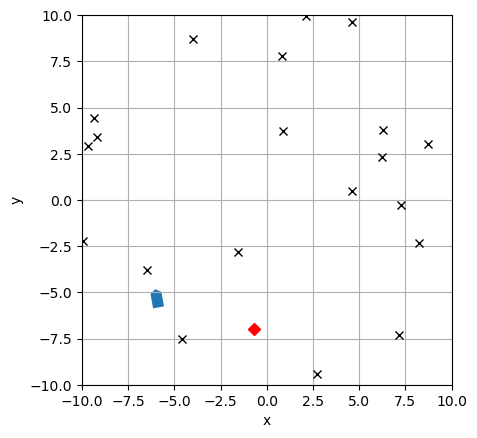

In [67]:
   ekf.run(T=20)

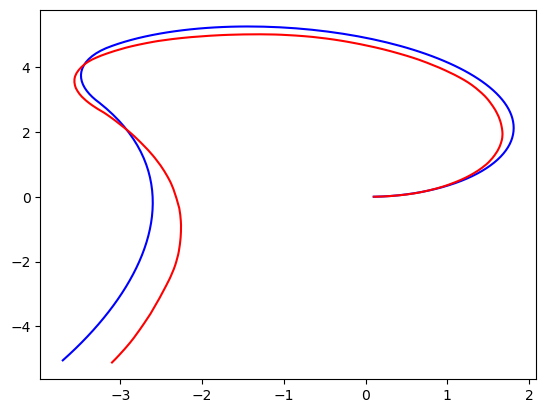

In [14]:
robot.plot_xy(color="b")
ekf.plot_xy(color="r")

In [15]:
P150 = ekf.get_P(150)

array([[  0.1666, -0.04335,  0.03476],
       [-0.04335,  0.09977, -0.01525],
       [ 0.03476, -0.01525,  0.01158]])

In [16]:
np.sqrt(P150[0, 0])

np.float64(0.4081316906810882)

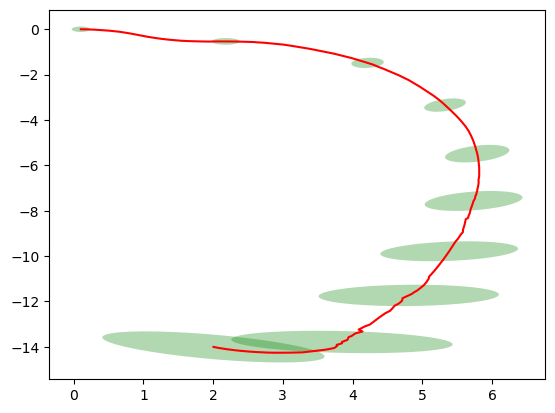

In [69]:
ekf.plot_xy(color="r")
ekf.plot_ellipse(filled=True, facecolor="g", alpha=0.3)
import matplotlib.pyplot as plt
plt.gcf().savefig(r"D:\robot_project\delivery-nav\baseline\rvc3_ekf_deadreckoning_xy_2026-11-03.png", dpi=150)

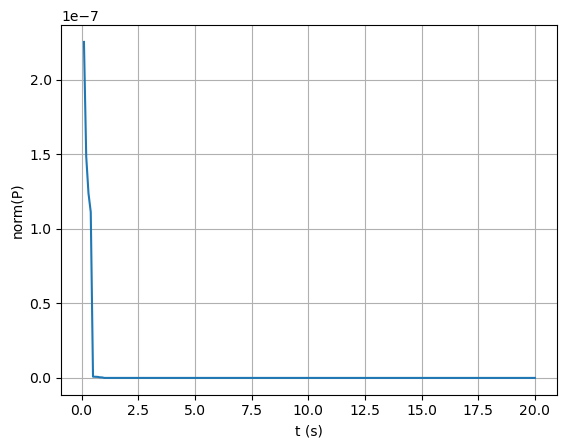

In [70]:
   import matplotlib.pyplot as plt
   t = ekf.get_t(); pn = ekf.get_Pnorm()
   plt.figure(); plt.plot(t, pn); plt.grid(True)
   plt.xlabel("t (s)"); plt.ylabel("norm(P)")
   plt.savefig(r"D:\robot_project\delivery-nav\baseline\rvc3_ekf_deadreckoning_pnorm_2026-11-03.png", dpi=150)

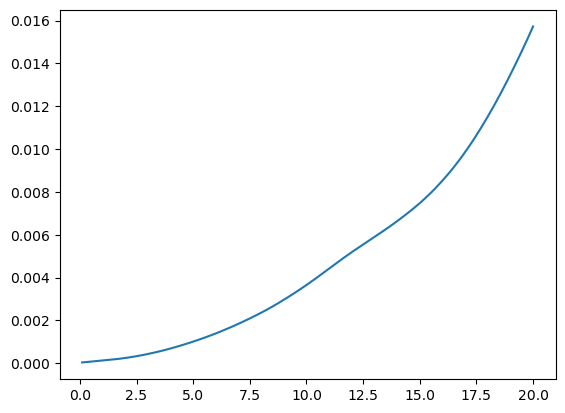

In [18]:
t = ekf.get_t();
pn = ekf.get_Pnorm();
plt.plot(t, pn);

# 6.2 Localizing with a Landmark Map


In [19]:
map = LandmarkMap(20, workspace=10)

LandmarkMap object with 20 landmarks, workspace=(-10.0: 10.0, -10.0: 10.0)

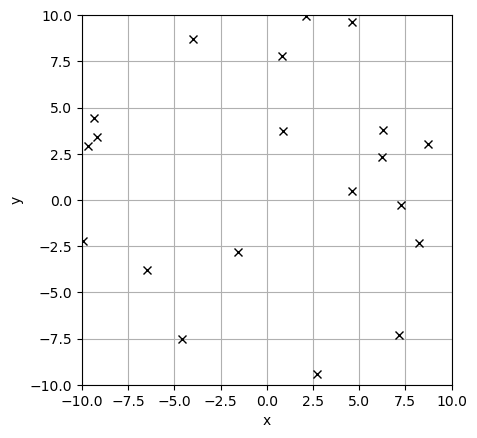

In [20]:
map.plot()

In [21]:
W = np.diag([0.1, np.deg2rad(1)]) ** 2;

In [22]:
sensor = RangeBearingSensor(robot=robot, map=map, covar=W,  
           angle=[-pi/2, pi/2], range=4, plot=True)

RangeBearingSensor sensor class
  LandmarkMap object with 20 landmarks, workspace=(-10.0: 10.0, -10.0: 10.0)
  W = [ 0.01, 0 | 0, 0.000305 ]
  sampled every 1 samples
  range: (0: 4)
  angle: (-1.57: 1.57)

In [23]:
z, i = sensor.reading()
# z
# i
print(f"landmark {i} at {z}")

landmark 15 at [    3.04   -1.559]


In [24]:
map[15]

array([  -6.487,   -3.795])

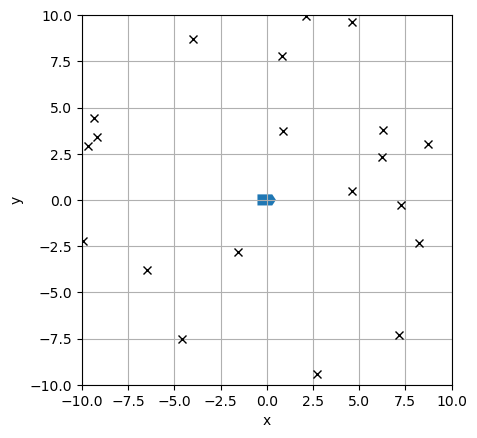

In [71]:
map = LandmarkMap(20, workspace=10);
V = np.diag([0.02, np.deg2rad(0.5)]) ** 2
robot = Bicycle(covar=V, animation="car");
robot.control = RandomPath(workspace=map, seed=0)
W = np.diag([0.1, np.deg2rad(1)]) ** 2
sensor = RangeBearingSensor(robot=robot, map=map, covar=W, 
           angle=[-pi/2, pi/2], range=4, seed=0, plot=True);
P0 = np.diag([0.05, 0.05, np.deg2rad(0.5)]) ** 2;
ekf = EKF(robot=(robot, V), P0=P0, map=map, sensor=(sensor, W));

In [26]:
# ekf.run(T=20)
html = ekf.run_animation(T=20, format="html")
HTML(html)

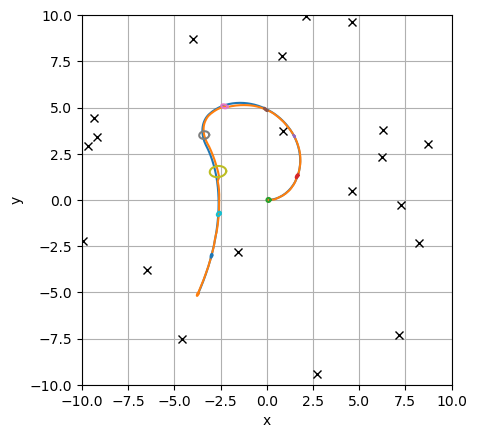

In [27]:
map.plot()
robot.plot_xy();
ekf.plot_xy();
ekf.plot_ellipse()

# 6.3 Creating a Landmark Map


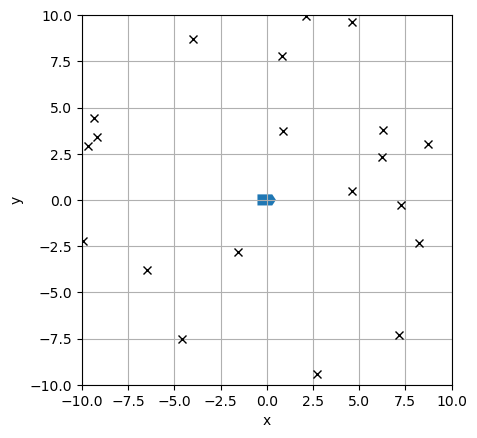

In [28]:
map = LandmarkMap(20, workspace=10, seed=0);
robot = Bicycle(covar=V, animation="car");
robot.control = RandomPath(workspace=map);
W = np.diag([0.1, np.deg2rad(1)]) ** 2
sensor = RangeBearingSensor(robot=robot, map=map, covar=W, 
           range=4, angle=[-pi/2, pi/2], plot=True);
ekf = EKF(robot=(robot, None), sensor=(sensor, W));

In [29]:
# ekf.run(T=100);

html = ekf.run_animation(T=100, format="html")
HTML(html)

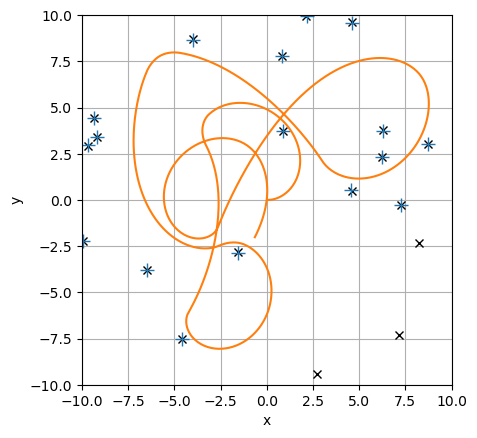

In [30]:
map.plot();
ekf.plot_map();
robot.plot_xy();

In [31]:
ekf.landmark(10)

(12, 22)

In [32]:
ekf.x_est[24:26]

array([   6.312,    3.756])

In [33]:
ekf.P_est[24:26, 24:26]

array([[0.0001317, 5.822e-06],
       [5.822e-06, 0.0002383]])

# 6.4 Simultaneous Localization and Mapping


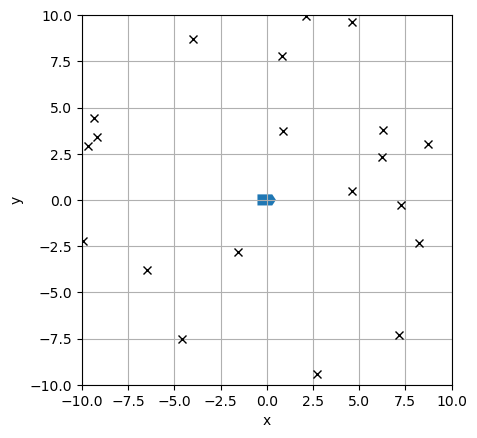

In [34]:
map = LandmarkMap(20, workspace=10);
W = np.diag([0.1, np.deg2rad(1)]) ** 2 
robot = Bicycle(covar=V, x0=(3, 6, np.deg2rad(-45)), 
          animation="car");
robot.control = RandomPath(workspace=map);
W = np.diag([0.1, np.deg2rad(1)]) ** 2
sensor = RangeBearingSensor(robot=robot, map=map, covar=W, 
           range=4, angle=[-pi/2, pi/2], plot=True);
P0 = np.diag([0.05, 0.05, np.deg2rad(0.5)]) ** 2;
ekf = EKF(robot=(robot, V), P0=P0, sensor=(sensor, W));

In [35]:
# ekf.run(T=40);

html = ekf.run_animation(T=40, format="html")
HTML(html)

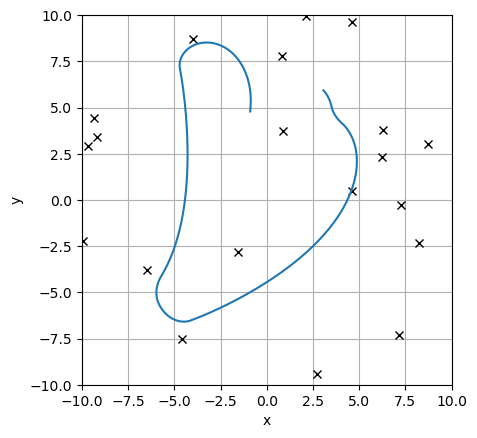

In [36]:
map.plot();       # plot true map
robot.plot_xy();  # plot true path

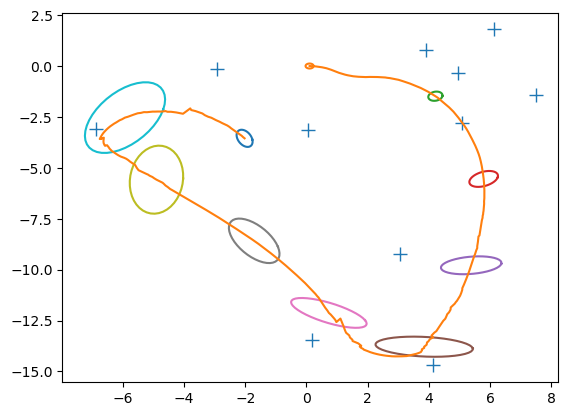

In [37]:
ekf.plot_map();      # plot estimated landmark position
ekf.plot_ellipse();  # plot estimated covariance
ekf.plot_xy();       # plot estimated robot path

In [38]:
T = ekf.get_transform(map)

   0.7088   -0.7054    2.101     
   0.7054    0.7088   -6.315     
   0         0         1         


# 6.5 Pose-Graph SLAM


NOTE. Minor changes to ensure Jupyter pretty printing of SymPy equations.  Introduced underscore to indicate subscripting, and changed `t` to `theta`
which is printed as $\theta$.

In [39]:
import sympy
xi, yi, ti, xj, yj, tj = sympy.symbols("x_i y_i theta_i x_j y_j theta_j")
xm, ym, tm = sympy.symbols("x_m y_m theta_m")
xi_e = SE2(xm, ym, tm).inv() * SE2(xi, yi, ti).inv() \
     * SE2(xj, yj, tj);
fk = sympy.Matrix(sympy.simplify(xi_e.xyt()));

In [40]:
Ai = sympy.simplify(fk.jacobian([xi, yi, ti]))
Ai.shape

(3, 3)

In [41]:
Ai

Matrix([
[-cos(theta_i + theta_m), -sin(theta_i + theta_m), x_i*sin(theta_i + theta_m) - x_j*sin(theta_i + theta_m) - y_i*cos(theta_i + theta_m) + y_j*cos(theta_i + theta_m)],
[ sin(theta_i + theta_m), -cos(theta_i + theta_m), x_i*cos(theta_i + theta_m) - x_j*cos(theta_i + theta_m) + y_i*sin(theta_i + theta_m) - y_j*sin(theta_i + theta_m)],
[                      0,                       0,                                                                                                                -1]])

In [42]:
pg = PoseGraph("data/pg1.g2o");

loaded g2o format file: 4 vertices, 4 edges


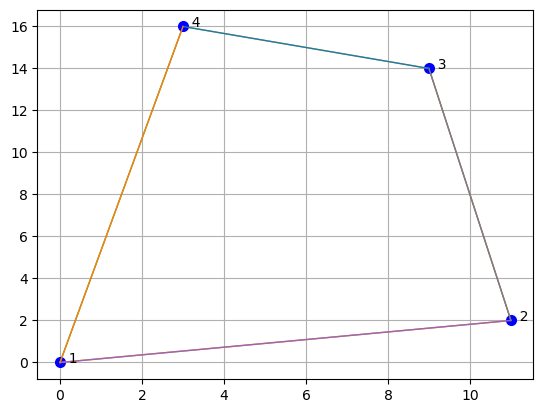

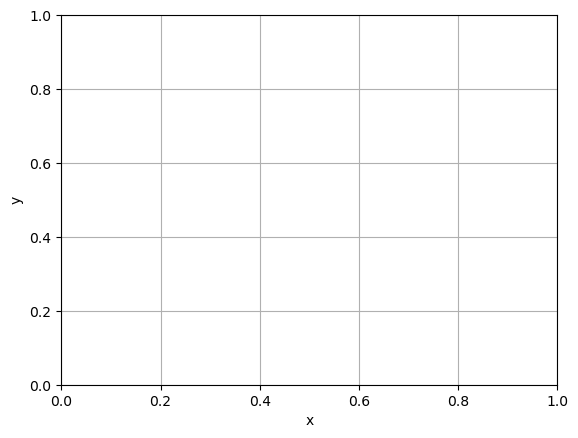

In [43]:
pg.plot();

done in 14.83 msec.  Total cost 316.88
done in 5.03 msec.  Total cost 47.2186
done in 2.07 msec.  Total cost 41.8271
done in 2.01 msec.  Total cost 0.566455
done in 2.01 msec.  Total cost 0.00378236
done in 2.01 msec.  Total cost 1.15234e-09
done in 2.01 msec.  Total cost 3.14139e-11
done in 0.00 msec.  Total cost 3.14139e-11


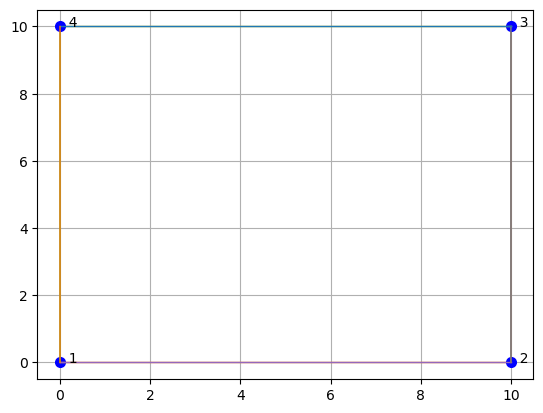

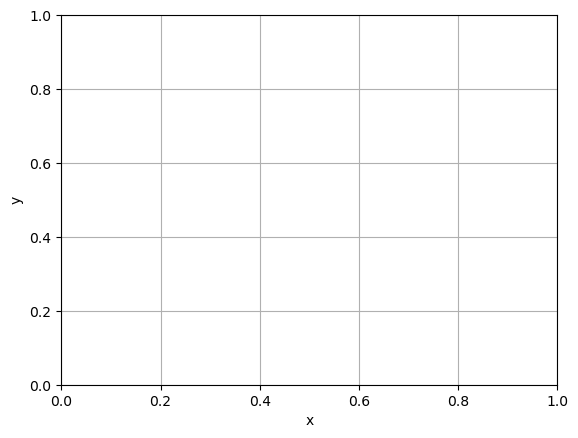

In [44]:
# pg.optimize(animate=True)

pg.optimize(animate=False)
pg.plot()

In [45]:
pg = PoseGraph("data/killian-small.toro");

loaded TORO/LAGO format file: 1941 vertices, 3995 edges


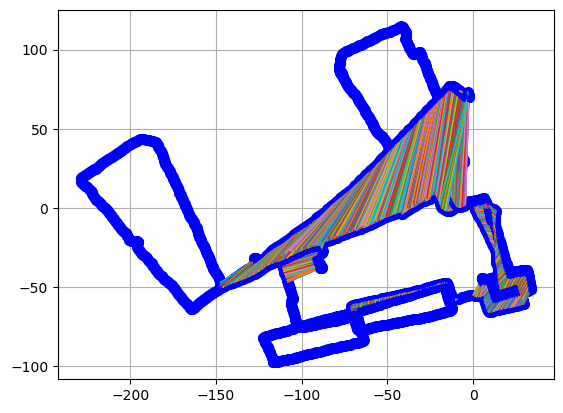

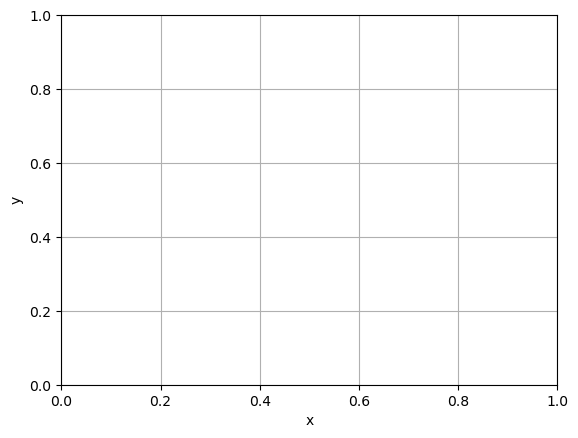

In [46]:
pg.plot(text=False)

done in 1538.21 msec.  Total cost 1.78135e+06
done in 1519.04 msec.  Total cost 1.39949e+06
done in 1499.89 msec.  Total cost 36.6762
done in 1539.67 msec.  Total cost 5.44579
done in 1502.30 msec.  Total cost 5.44565
done in 1618.66 msec.  Total cost 5.44567


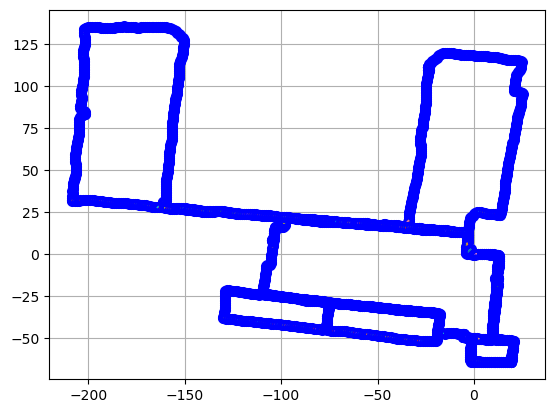

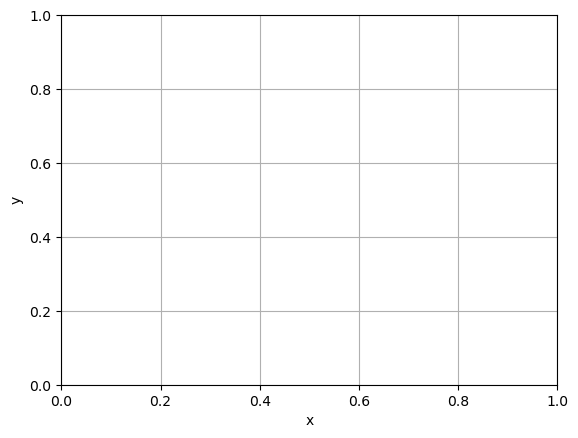

In [47]:
pg.optimize()
pg.plot(text=False)

# 6.6 Sequential Monte-Carlo Localization


In [48]:
map = LandmarkMap(20, workspace=10);

In [49]:
V = np.diag([0.02, np.deg2rad(0.5)]) ** 2;
robot = Bicycle(covar=V, animation="car", workspace=map);
robot.control = RandomPath(workspace=map)

In [50]:
W = np.diag([0.1, np.deg2rad(1)]) ** 2;
sensor = RangeBearingSensor(robot, map, covar=W, plot=True);

In [51]:
R = np.diag([0.1, 0.1, np.deg2rad(1)]) ** 2;

In [52]:
L = np.diag([0.1, 0.1]);

In [53]:
pf = ParticleFilter(robot, sensor=sensor, R=R, L=L, nparticles=1000, animate=True);

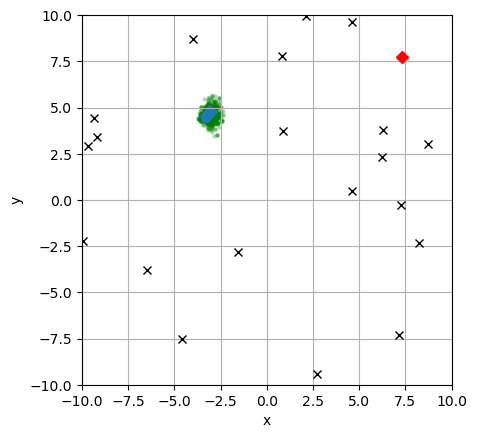

In [54]:
# pf.run(T=10);

html = pf.run_animation(T=10, format="html");
HTML(html)

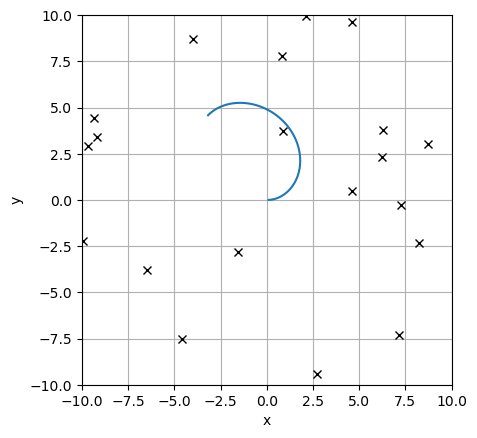

In [55]:
map.plot();
robot.plot_xy();

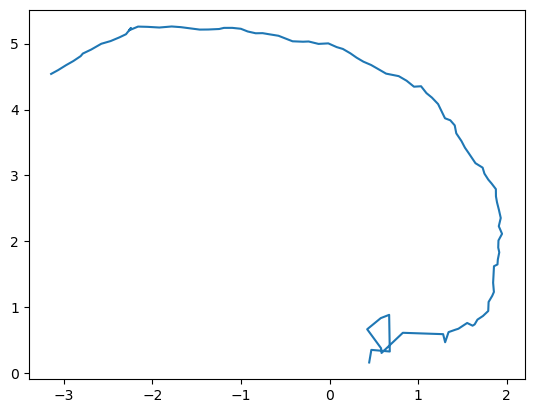

In [56]:
pf.plot_xy();

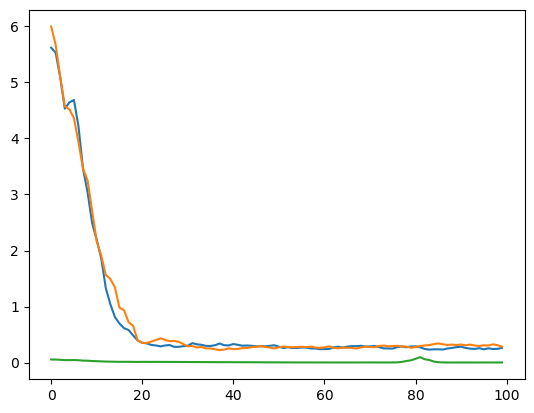

In [57]:
plt.plot(pf.get_std()[:100,:]);

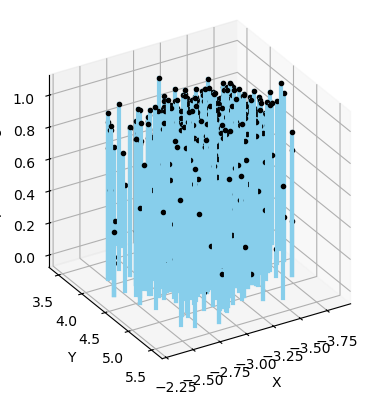

In [58]:
pf.plot_pdf()

# 6.8 Application: Lidar


## 6.8.1 Lidar-based Odometry


In [59]:
pg = PoseGraph("data/killian.g2o.zip", lidar=True);

loaded g2o format file: 3873 vertices, 4987 edges
  3873 lidar scans: 180 beams, fov -90.0° to 90.0°, max range 50.0


In [60]:
[r, theta] = pg.scan(100);
r.shape
theta.shape

(180,)

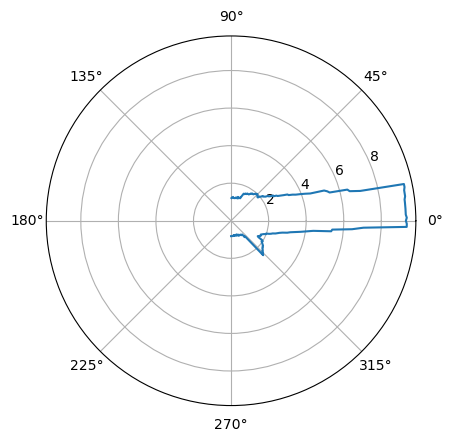

In [61]:
plt.clf()
plt.polar(theta, r);

In [62]:
p100 = pg.scanxy(100);
p101 = pg.scanxy(100);
p100.shape

(2, 180)

In [63]:
T = pg.scanmatch(100, 101);
T.printline()

ITER 0 999997.596411268 2.4035887320061287
ITER 1 0.7221130437464818 1.6814756882596469
ITER 2 0.39237915196944817 1.2890965362901987
ITER 3 0.6410190269219497 0.648077509368249
ITER 4 0.18601299152934525 0.4620645178389038
ITER 5 0.061131785319156196 0.4009327325197476
ITER 6 0.05149040620395323 0.34944232631579436
ITER 7 0.04214481043907564 0.3072975158767187
ITER 8 0.03321627508917324 0.2740812407875455
ITER 9 0.10215952758433514 0.17192171320321034
ITER 10 0.005432907099160417 0.16648880610404992
ITER 11 0.005289990692387975 0.16119881541166195
ITER 12 0.002503931709508661 0.1586948837021533
ITER 13 0.002187693034604754 0.16088257673675804
ITER 14 2.6928311810031635e-05 0.160855648424948
t = 0.506, -0.00872; 2.93°


In [64]:
pg.time(101) - pg.time(100)

1.7599999904632568

## 6.8.2 Lidar-based Map Building


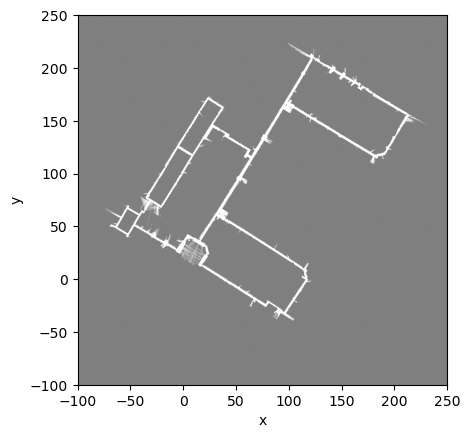

In [65]:
og = OccupancyGrid(workspace=[-100, 250, -100, 250], cellsize=0.1, value=np.int32(0));
pg.scanmap(og, maxrange=40)
og.plot(cmap="gray")